# 08 — Extra: Classificação com Mais de Duas Classes

Na trilha principal (notebooks 01 a 07), o alvo tinha só **duas** classes: `<=50K` e `>50K`. Muitos problemas reais têm **mais**: reconhecer qual dígito foi escrito à mão (10 classes), qual a espécie de uma planta, qual o tipo de um defeito numa peça, qual o assunto de um e-mail...

Neste notebook extra vamos ver o que muda quando há **várias classes** (classificação **multiclasse**):
- Como os modelos lidam com várias classes: **um-contra-todos** e **softmax**
- A **matriz de confusão** com 10 classes, e o que ela revela sobre os erros
- **Métricas por classe** e as três formas de resumi-las: médias **macro**, **micro** e **ponderada**
- O que acontece quando algumas classes são **raras**
- Por que o **melhor modelo depende do problema**: aqui, o resultado é bem diferente do Adult

Usaremos um dataset novo: os **dígitos escritos à mão** (`load_digits`), que já vem no scikit-learn.

> Este notebook leva menos de **30 segundos** para rodar.

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Ferramentas novas deste notebook:
from sklearn.datasets import load_digits                  # dígitos escritos à mão (vem com o scikit-learn)
from sklearn.multiclass import OneVsRestClassifier        # estratégia "um contra todos"
from sklearn.metrics import classification_report         # relatório com as métricas de cada classe
from sklearn.metrics import precision_score, recall_score, f1_score

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100

digitos = load_digits()
X = digitos.data     # um array do NumPy: uma linha por imagem, uma coluna por pixel
y = digitos.target   # o dígito (0 a 9) de cada imagem

print(f"X: {X.shape}  ->  {X.shape[0]} imagens, cada uma com {X.shape[1]} pixels")
print(f"Valores dos pixels: de {X.min():.0f} (branco) a {X.max():.0f} (preto)")
# np.bincount conta quantas vezes aparece cada número inteiro: quantas imagens de cada dígito.
print("Imagens de cada dígito:", np.bincount(y))

X: (1797, 64)  ->  1797 imagens, cada uma com 64 pixels
Valores dos pixels: de 0 (branco) a 16 (preto)
Imagens de cada dígito: [178 182 177 183 181 182 181 179 174 180]


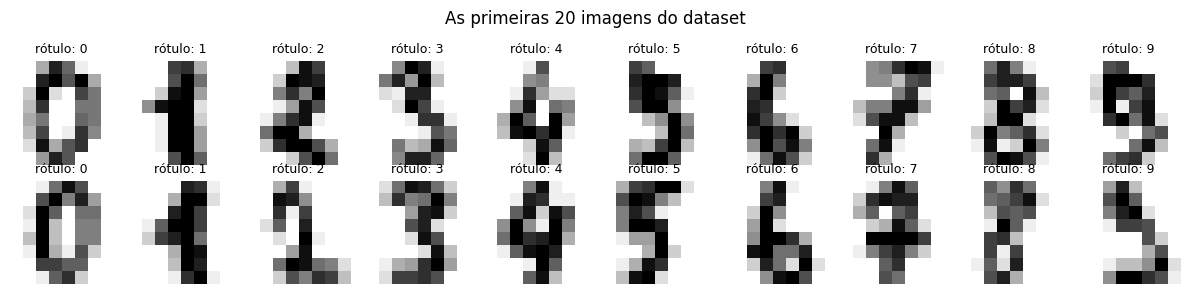

In [2]:
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for i, ax in enumerate(axes.ravel()):
    # digitos.images guarda as mesmas imagens no formato 8 × 8, prontas para desenhar.
    ax.imshow(digitos.images[i], cmap="gray_r")   # gray_r: 0 = branco, 16 = preto
    ax.set_title(f"rótulo: {y[i]}", fontsize=9)
    ax.axis("off")   # esconde os eixos
plt.suptitle("As primeiras 20 imagens do dataset")
plt.tight_layout()
plt.show()

## 🎓 Conceito: uma imagem é uma tabela de números

Para o modelo, uma imagem é só uma **lista de números**. Cada imagem do dataset tem 8 × 8 = **64 pixels**, e cada pixel é um número de 0 (branco) a 16 (preto). "Achatando" a grade de 8 × 8 numa única linha, cada imagem vira uma linha com 64 colunas, exatamente como uma pessoa do Adult era uma linha com 12 colunas.

O modelo não "vê" um 7: ele aprende que, quando certos pixels estão escuros e outros claros, a imagem costuma ser um 7.

**Conclusão:** o dataset tem **1.797 imagens**, com cerca de **180 de cada dígito**. As classes estão praticamente **equilibradas**, ao contrário do Adult (24% × 76%). Vamos usar a mesma receita da trilha: separar um teste estratificado e tomar as decisões com validação cruzada estratificada.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Treino: {len(X_train)} imagens   Teste (guardado): {len(X_test)} imagens")

Treino: 1437 imagens   Teste (guardado): 360 imagens


## 🎓 Conceito: como um classificador lida com várias classes

A regressão logística do notebook 02 calcula **uma** pontuação $z$ e a transforma numa probabilidade com a sigmoide. Isso funciona para duas classes. Com 10 classes, existem duas estratégias:

**1. Um contra todos (*one-vs-rest*, OvR):** treina **10 modelos binários**, um para cada dígito: "é 0 ou não?", "é 1 ou não?", ..., "é 9 ou não?". Para uma imagem nova, os 10 modelos dão a sua probabilidade, e vence o dígito com a **maior**. É como 10 especialistas, cada um só sabendo reconhecer o seu número.

**2. Softmax (multinomial):** treina **um único modelo** que calcula **10 pontuações** ao mesmo tempo, uma por dígito, e as transforma em probabilidades com a função **softmax**:

$$P(\text{classe } k) = \frac{e^{z_k}}{e^{z_0} + e^{z_1} + \dots + e^{z_9}}$$

A softmax é a "sigmoide para várias classes": transforma as pontuações em números entre 0 e 1 que **somam exatamente 1**. A classe com a maior pontuação fica com a maior probabilidade.

Analogia: numa eleição com 10 candidatos, a softmax é a apuração que transforma os "votos" (as pontuações) em **porcentagens** que somam 100%. O um-contra-todos é como fazer 10 pesquisas separadas, uma para cada candidato ("você votaria nele, sim ou não?"), que não necessariamente somam 100%.

A `LogisticRegression` do scikit-learn usa a **softmax** automaticamente quando há mais de duas classes. Muitos outros modelos (KNN, árvores, boosting) lidam com várias classes naturalmente.

## 2. A softmax "à mão"

In [4]:
logistica = Pipeline([
    ("padronizar", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=2000)),
])
logistica.fit(X_train, y_train)

imagem = X_test[[0]]   # [[0]]: uma tabela com 1 linha (a primeira imagem do teste)

# decision_function devolve as 10 pontuações z da imagem, uma por dígito.
pontuacoes = logistica.decision_function(imagem)[0]
# A softmax "à mão": e elevado a cada pontuação, dividido pela soma de todos.
softmax_mao = np.exp(pontuacoes) / np.exp(pontuacoes).sum()

tabela_softmax = pd.DataFrame({
    "pontuação z": pontuacoes,
    "softmax à mão": softmax_mao,
    "predict_proba": logistica.predict_proba(imagem)[0],
}, index=[f"dígito {d}" for d in range(10)])
display(tabela_softmax)
print(f"Soma das probabilidades: {softmax_mao.sum():.4f}")
print(f"Previsão: {logistica.predict(imagem)[0]}   Rótulo verdadeiro: {y_test[0]}")

,pontuação z,softmax à mão,predict_proba
dígito 0,0.8107,1.1307e-04,1.1307e-04
dígito 1,-8.1210,1.4940e-08,1.4940e-08
dígito 2,-6.5319,7.3195e-08,7.3195e-08
dígito 3,-0.8427,2.1642e-05,2.1642e-05
dígito 4,-0.8669,2.1124e-05,2.1124e-05
dígito 5,9.8127,9.1801e-01,9.1801e-01
dígito 6,0.9981,1.3637e-04,1.3637e-04
dígito 7,-4.8576,3.9051e-07,3.9051e-07
dígito 8,2.2108,4.5854e-04,4.5854e-04
dígito 9,7.3879,8.1240e-02,8.1240e-02


Soma das probabilidades: 1.0000
Previsão: 5   Rótulo verdadeiro: 5


**Conclusão:** a softmax "à mão" deu exatamente os mesmos números do `predict_proba`, e as 10 probabilidades somam **1**.
- O dígito **5** tem a maior pontuação (**9,81**) e fica com **91,8%** de probabilidade.
- O dígito **9** vem em segundo (pontuação 7,39), com **8,1%**: o modelo enxerga alguma semelhança entre esse 5 e um 9.
- Todos os outros ficam abaixo de 0,1%.

Repare no efeito da exponencial: uma diferença de 2,4 pontos entre o 5 e o 9 virou uma diferença de 11 vezes na probabilidade (91,8% contra 8,1%). A softmax **amplifica** as diferenças, por isso ela costuma produzir uma classe claramente vencedora.

## 3. Softmax × um contra todos

In [5]:
um_contra_todos = Pipeline([
    ("padronizar", StandardScaler()),
    # OneVsRestClassifier "embrulha" um modelo binário e treina uma cópia dele para cada classe.
    ("modelo", OneVsRestClassifier(LogisticRegression(max_iter=2000))),
])

resultados = {}
for nome, modelo in [("Logística softmax", logistica), ("Logística um contra todos", um_contra_todos)]:
    # f1_macro: o F1 para várias classes (seção 5). roc_auc_ovr: a AUC calculada "um contra todos".
    cv_resultado = cross_validate(modelo, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro", "roc_auc_ovr"])
    resultados[nome] = {
        "acurácia": cv_resultado["test_accuracy"].mean(),
        "± desvio": cv_resultado["test_accuracy"].std(),
        "F1 macro": cv_resultado["test_f1_macro"].mean(),
        "AUC (um contra todos)": cv_resultado["test_roc_auc_ovr"].mean(),
    }
pd.DataFrame(resultados).T

,acurácia,± desvio,F1 macro,AUC (um contra todos)
Logística softmax,0.9680,0.0074,0.9679,0.9991
Logística um contra todos,0.9645,0.0109,0.9643,0.9983


**Conclusão:** as duas estratégias funcionam bem e ficam praticamente **empatadas**: acurácia de **96,80%** com a softmax e **96,45%** com o um contra todos, uma diferença menor que os desvios padrão (~0,7 a 1,1 ponto). A softmax tem uma pequena vantagem prática: treina **um** modelo em vez de 10, e as probabilidades já saem somando 1.

Repare também na **AUC um contra todos** (0,999): é a média das AUCs de cada dígito contra os demais. Ela é quase perfeita porque, para cada dígito, o modelo quase sempre dá probabilidade maior a ele do que aos outros. Mas a AUC alta convive com 3% de erros, por isso, em problemas multiclasse, a matriz de confusão e as métricas por classe costumam ser mais informativas.

## 🎓 Conceito: a matriz de confusão com várias classes

A matriz de confusão do notebook 02 tinha 2 × 2 casas. Com 10 classes, ela tem **10 × 10**:
- Cada **linha** é o dígito **verdadeiro**; cada **coluna** é o dígito **previsto**.
- A **diagonal** são os acertos.
- **Fora da diagonal** estão os erros, e agora eles têm **endereço**: a casa (linha 8, coluna 1) conta quantos 8 foram confundidos com 1.

Com duas classes, só existia um tipo de "erro para cada lado". Com várias classes, a matriz mostra **quais pares** o modelo confunde, o que ajuda a entender o porquê.

## 4. Quais dígitos o modelo confunde?

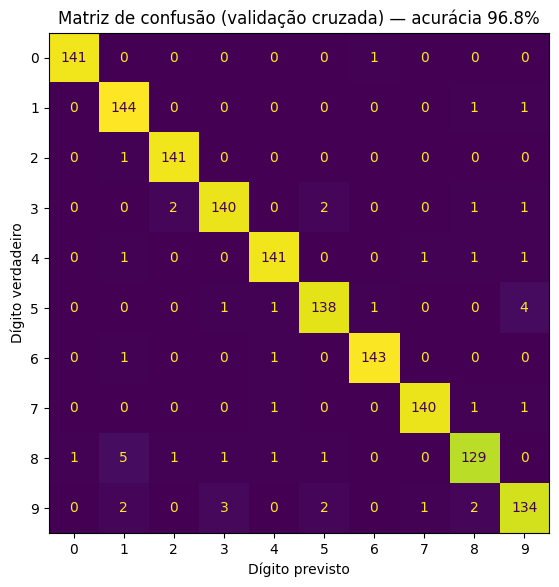

,verdadeiro,previsto,erros
81,8,1,5
59,5,9,4
93,9,3,3
32,3,2,2
91,9,1,2


In [6]:
# Previsões "fora da dobra" de cada imagem do treino, como no notebook 02.
previsoes = cross_val_predict(logistica, X_train, y_train, cv=cv)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay.from_predictions(y_train, previsoes, colorbar=False, ax=ax)
ax.set_xlabel("Dígito previsto")
ax.set_ylabel("Dígito verdadeiro")
ax.set_title(f"Matriz de confusão (validação cruzada) — acurácia {accuracy_score(y_train, previsoes):.1%}")
plt.show()

# Os pares mais confundidos: zeramos a diagonal (os acertos) e procuramos os maiores valores.
matriz = confusion_matrix(y_train, previsoes)
np.fill_diagonal(matriz, 0)   # coloca 0 em todas as casas da diagonal
pares = pd.DataFrame(
    [(verdadeiro, previsto, matriz[verdadeiro, previsto]) for verdadeiro in range(10) for previsto in range(10)],
    columns=["verdadeiro", "previsto", "erros"],
).sort_values("erros", ascending=False)
pares.head(5)

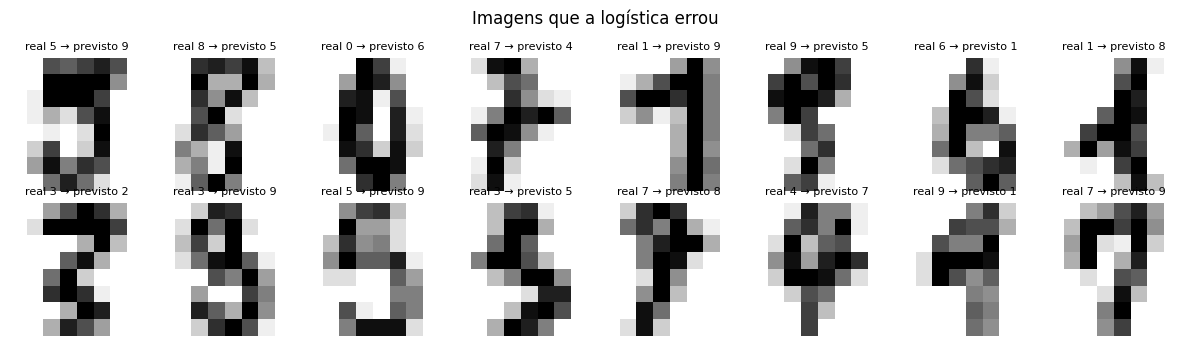

In [7]:
# Vamos ver algumas imagens que o modelo errou. np.where devolve as posições onde a condição é verdadeira.
posicoes_erros = np.where(previsoes != y_train)[0]

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, posicao in zip(axes.ravel(), posicoes_erros[:16]):
    ax.imshow(X_train[posicao].reshape(8, 8), cmap="gray_r")   # reshape(8, 8): volta a linha de 64 pixels para a grade
    ax.set_title(f"real {y_train[posicao]} → previsto {previsoes[posicao]}", fontsize=8)
    ax.axis("off")
plt.suptitle("Imagens que a logística errou")
plt.tight_layout()
plt.show()

**Conclusão:** a matriz de confusão mostra que os erros **não** são espalhados ao acaso:
- O par mais confundido é **8 → 1** (5 vezes), seguido de **5 → 9** (4 vezes) e **9 → 3** (3 vezes).
- O **8** é o dígito com mais erros: só **129** dos 139 foram reconhecidos.
- Nas imagens erradas, dá para entender boa parte das confusões: com só 8 × 8 pixels, vários desses dígitos estão borrados ou incompletos, e mesmo uma pessoa hesitaria em alguns. Um 5 com a parte de cima fechada vira um 9; um 8 fino e alto lembra um 1.

Essa é a maior vantagem da matriz de confusão multiclasse: ela não diz só **quanto** o modelo erra, mas **o que** ele confunde com **o quê**. Com isso dá para pensar em soluções específicas (por exemplo, mais exemplos de 8 e 9 para o treino).

## 🎓 Conceito: métricas por classe e as médias macro, micro e ponderada

Precisão, recall e F1 (notebook 04) foram definidos para **uma** classe positiva. Com várias classes, calculamos as três **para cada classe**, tratando-a como "a positiva" e todas as outras como "negativas". Por exemplo, o recall do dígito 8 é: dos 8 verdadeiros, quantos o modelo reconheceu como 8?

Isso dá 10 valores de cada métrica. Para resumi-los num número, existem três médias:
- **Macro:** a média simples das 10 classes. **Cada classe pesa igual**, seja ela comum ou rara.
- **Ponderada** (*weighted*): a média pesada pelo número de exemplos de cada classe. Classes comuns pesam mais.
- **Micro:** junta os acertos e erros de **todas** as classes antes de calcular. Para precisão, recall e F1, a média micro é igual à **acurácia**.

Analogia: uma escola com 10 turmas de tamanhos diferentes. A média **macro** é a média das notas médias de cada turma (cada turma vale o mesmo). A **ponderada** e a **micro** são a média de todos os alunos juntos (turmas grandes valem mais). Se uma turma pequena vai muito mal, só a média macro denuncia.

## 5. O relatório por classe

In [8]:
# classification_report calcula precisão, recall e F1 de cada classe e as médias.
# output_dict=True devolve um dicionário, que transformamos em tabela.
relatorio = pd.DataFrame(classification_report(y_train, previsoes, output_dict=True)).T
relatorio = relatorio.rename(columns={"precision": "precisão", "f1-score": "F1", "support": "imagens"})
relatorio

,precisão,recall,F1,imagens
0,0.9930,0.9930,0.9930,142.000
1,0.9351,0.9863,0.9600,146.000
2,0.9792,0.9930,0.9860,142.000
3,0.9655,0.9589,0.9622,146.000
4,0.9724,0.9724,0.9724,145.000
5,0.9650,0.9517,0.9583,145.000
6,0.9862,0.9862,0.9862,145.000
7,0.9859,0.9790,0.9825,143.000
8,0.9556,0.9281,0.9416,139.000
9,0.9437,0.9306,0.9371,144.000


**Conclusão:** - O relatório confirma a matriz: os dígitos mais difíceis são o **9** (F1 0,937) e o **8** (F1 0,942); os mais fáceis, o **0** (0,993), o **2** e o **6** (0,986).
- O **1** tem um padrão interessante: recall alto (98,6%), mas a **menor precisão** (93,5%). Quase todos os 1 são reconhecidos, mas o modelo também chama de "1" vários outros dígitos (lembre dos 8 → 1).
- **As três médias são praticamente iguais** (0,968): macro, ponderada e a acurácia (que é a média micro). Isso acontece porque as classes têm quase o mesmo tamanho (de 139 a 146 imagens), então "cada classe pesa igual" e "cada imagem pesa igual" dão quase o mesmo resultado.

## 6. E quando algumas classes são raras?

Nos dígitos, todas as classes têm ~180 imagens, e por isso as três médias coincidem. Para ver a diferença, vamos **simular** um problema desbalanceado: manter todas as imagens dos dígitos 0 a 7, mas só **10%** das imagens de **8** e de **9**. É uma situação artificial, mas comum na prática (pense em defeitos raros numa linha de produção).

In [9]:
gerador = np.random.default_rng(42)
# Para cada imagem: se for 8 ou 9, mantém com 10% de chance; senão, mantém sempre.
manter = np.where(np.isin(y_train, [8, 9]), gerador.random(len(y_train)) < 0.10, True)
X_raro, y_raro = X_train[manter], y_train[manter]
print("Imagens de cada dígito no conjunto desbalanceado:", np.bincount(y_raro))

previsoes_raro = cross_val_predict(logistica, X_raro, y_raro, cv=cv)

medias = pd.DataFrame({
    media: {
        "precisão": precision_score(y_raro, previsoes_raro, average=media),
        "recall": recall_score(y_raro, previsoes_raro, average=media),
        "F1": f1_score(y_raro, previsoes_raro, average=media),
    }
    for media in ["micro", "weighted", "macro"]   # average= escolhe o tipo de média
}).T
medias.index = ["micro (= acurácia)", "ponderada", "macro"]
display(medias)

# O recall das classes raras, comparado com o das classes comuns:
recall_por_classe = recall_score(y_raro, previsoes_raro, average=None)   # average=None: um valor por classe
# float(...) converte cada número do NumPy num float comum, que é exibido de forma mais limpa.
print("Recall de cada dígito:", {digito: round(float(r), 2) for digito, r in enumerate(recall_por_classe)})

Imagens de cada dígito no conjunto desbalanceado: [142 146 142 146 145 145 145 143  13  14]


,precisão,recall,F1
micro (= acurácia),0.9763,0.9763,0.9763
ponderada,0.9765,0.9763,0.9758
macro,0.9421,0.9069,0.9199


Recall de cada dígito: {0: 1.0, 1: 0.99, 2: 0.99, 3: 0.98, 4: 0.98, 5: 0.97, 6: 0.99, 7: 0.99, 8: 0.62, 9: 0.57}


**Conclusão:** com os dígitos 8 e 9 raros (13 e 14 imagens, contra ~145 dos outros), as médias se **separam**:
- A **acurácia** (média micro) foi para **97,6%**, ainda **maior** que os 96,8% do conjunto equilibrado. A **média ponderada** conta a mesma história (F1 0,976).
- A **média macro** caiu para **0,920** de F1, e o recall macro, para **0,907**.
- O motivo aparece no recall por classe: o modelo reconhece só **62%** dos 8 e **57%** dos 9, contra 97% a 100% dos outros dígitos.

É a lição do notebook 02 de volta, agora com várias classes: a acurácia e a média ponderada são dominadas pelas classes **comuns** e escondem que o modelo vai mal nas **raras**. A **média macro** dá a cada classe o mesmo peso e denuncia o problema. Quando as classes raras importam (o defeito raro, a doença rara), olhe a média macro e o recall de cada classe.

## 7. Outros classificadores nos dígitos

No notebook 05, o gradient boosting venceu com folga no Adult, e o KNN ficou abaixo da regressão logística. Será que é sempre assim? Vamos comparar os mesmos tipos de modelo nos dígitos (de volta ao conjunto completo, equilibrado).

In [10]:
modelos = {
    "Logística (softmax)": logistica,
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3),   # os pixels já estão todos na mesma escala (0 a 16)
    "SVM (kernel RBF)": Pipeline([("padronizar", StandardScaler()), ("modelo", SVC())]),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=42),
}

comparacao = {}
for nome, modelo in modelos.items():
    # ⏱️ O gradient boosting é o mais lento aqui (~10 segundos): ele treina árvores para CADA uma das 10 classes.
    cv_resultado = cross_validate(modelo, X_train, y_train, cv=cv, scoring=["accuracy", "f1_macro"])
    comparacao[nome] = {
        "acurácia": cv_resultado["test_accuracy"].mean(),
        "± desvio": cv_resultado["test_accuracy"].std(),
        "F1 macro": cv_resultado["test_f1_macro"].mean(),
        "tempo de treino (s)": cv_resultado["fit_time"].sum(),
    }
pd.DataFrame(comparacao).T.sort_values("acurácia", ascending=False)

,acurácia,± desvio,F1 macro,tempo de treino (s)
KNN (k=3),0.9868,0.0056,0.9867,0.0025
SVM (kernel RBF),0.9812,0.0061,0.9812,0.1026
Gradient boosting,0.9701,0.0109,0.9699,6.9796
Logística (softmax),0.9680,0.0074,0.9679,0.0806


**Conclusão:** o resultado é bem diferente do que vimos no Adult:
- O **KNN** com só 3 vizinhos, o modelo mais simples de todos, é o **melhor**: acurácia de **98,68%**. Ele também é o mais rápido de treinar (não treina nada!).
- O **SVM** vem em seguida (**98,12%**). Com só ~1.150 imagens de treino em cada dobra, o custo que tornava o SVM inviável no Adult não pesa aqui.
- O **gradient boosting**, campeão no Adult, fica em terceiro (**97,01%**) e é de longe o mais lento: ~7 segundos de treino, contra milésimos de segundo do KNN.
- A **logística** fica por último (**96,80%**).

Por que o KNN vai tão bem aqui? Porque nas imagens a **distância faz sentido**: duas imagens do mesmo dígito têm pixels parecidos, e todos os 64 pixels estão na mesma escala (0 a 16) e têm o mesmo significado. No Adult, a distância misturava idade, dólares e dezenas de colunas de 0/1, e "vizinho" significava pouco.

**Lição:** **não existe um classificador que seja o melhor sempre.** Cada família de modelos tem pontos fortes que combinam com certos tipos de dados. É por isso que comparamos vários modelos com validação cruzada, em vez de escolher pela fama.

Uma ressalva honesta: usamos k = 3 sem testar outros valores, e o SVM e o boosting com as configurações padrão. Com ajustes, a ordem entre os três primeiros poderia mudar um pouco.

## 8. Avaliação final no teste

Escolhido o modelo pela validação cruzada, avaliamos uma única vez no teste.

Acurácia no teste: 98.61%
F1 macro no teste: 0.9859
Erros: 5 de 360 imagens


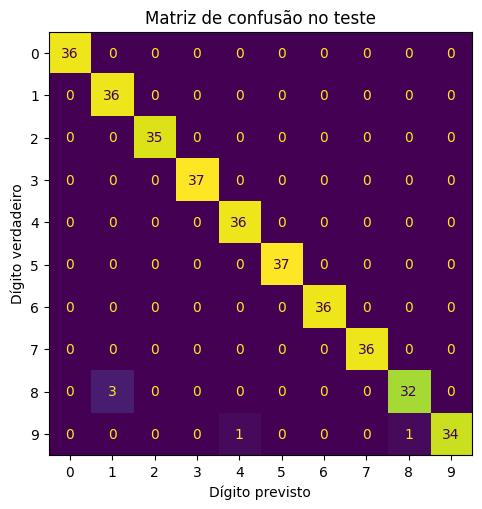

In [11]:
modelo_escolhido = modelos["KNN (k=3)"]   # o de maior acurácia na validação cruzada
modelo_escolhido.fit(X_train, y_train)
previsao_teste = modelo_escolhido.predict(X_test)

print(f"Acurácia no teste: {accuracy_score(y_test, previsao_teste):.2%}")
print(f"F1 macro no teste: {f1_score(y_test, previsao_teste, average='macro'):.4f}")
print(f"Erros: {(previsao_teste != y_test).sum()} de {len(y_test)} imagens")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, previsao_teste, colorbar=False, ax=ax)
ax.set_xlabel("Dígito previsto")
ax.set_ylabel("Dígito verdadeiro")
ax.set_title("Matriz de confusão no teste")
plt.show()

**Conclusão:** no teste, o KNN acertou **98,61%** das imagens (F1 macro de 0,986), praticamente igual aos 98,68% da validação cruzada. Ele errou só **5 das 360 imagens**, e os erros se concentram exatamente onde a validação cruzada apontava: três **8 viraram 1**, um **9 virou 4** e outro **9 virou 8**. Os dígitos 0 a 7 foram reconhecidos sem nenhum erro.

## 9. Resumo

**Resultados (validação cruzada no treino)**

| Modelo | Acurácia | F1 macro |
|---|---|---|
| Logística (softmax) | 96,80% | 0,968 |
| Logística (um contra todos) | 96,45% | 0,964 |
| Gradient boosting | 97,01% | 0,970 |
| SVM (kernel RBF) | 98,12% | 0,981 |
| **KNN (k = 3)** | **98,68%** | **0,987** |

No teste, o KNN acertou **98,61%** das imagens.

**Conceitos que você aprendeu**
- **Classificação multiclasse** e as duas estratégias: **um contra todos** (vários modelos binários) e **softmax** (um modelo, probabilidades que somam 1).
- Uma **imagem** é uma tabela de números: um pixel por coluna.
- A **matriz de confusão** multiclasse mostra **quais pares** de classes o modelo confunde.
- **Métricas por classe** e as médias **macro** (cada classe pesa igual), **ponderada** e **micro** (= acurácia).
- Com classes raras, só a **média macro** e o **recall por classe** denunciam um modelo que vai mal nelas.
- **Não existe um classificador universalmente melhor:** o KNN, fraco no Adult, foi o melhor nas imagens.

**Python novo:** `load_digits`, `np.bincount`, `imshow`, `ax.axis("off")`, `decision_function`, `OneVsRestClassifier`, `np.fill_diagonal`, list comprehension com dois `for`, `reshape(8, 8)`, `classification_report(output_dict=True)`, `average=` nas métricas, `np.isin` e `enumerate` num dict comprehension.

Com este notebook, você conheceu os principais tipos de problema de classificação: binária e multiclasse, com classes equilibradas e desbalanceadas, com dados tabulares e com imagens.